# 02 · BC-RNN baseline (state-based): Can

**Purpose.** Phase 1 result: how well the upstream paper BC-RNN (low-dim, ph data) solves
Can in closed loop, which checkpoint to carry forward, and how it fails. Uses the protocol of
00b: paired rollouts on a selection seed, one fresh report seed for the chosen checkpoint,
Wilson intervals, exact McNemar for paired comparisons. Square is added as a second section
once its runs exist.

| | |
|---|---|
| Track | A (upstream training and rollouts; analysis only, no simulation) |
| Kernel | sim venv ("franka sim"); `numpy`, `scipy`, `matplotlib`; `src/franka_il/eval_stats.py` |
| Inputs | `results/can_eval_episodes.csv` (committed; built by `jobs/collect_eval.py` from eval jobs 5949705 and 5950799); clips in `docs/media/` |
| Outputs | `docs/figures/can_eval_success.png`, `docs/figures/can_eval_paired.png` |
| Runtime | seconds |
| Success check | all assertions pass; the report-seed number and its interval match docs/BASELINE.md |

**Runs.** Training job 5929929 (CPU, 2000 epochs, paper config `configs/can/bc_rnn_low_dim.json`,
3 h 35 min). Evaluation on `sim` (robosuite 1.5.2, MuJoCo 3.9.0): 50 rollouts, horizon 400,
seed 0 for all 20 checkpoints (job 5949705), seed 1 for the selected one (job 5950799).
State-based: the policy sees robot proprioception and the 14-D object vector (chapter 01),
no images.

## 0. Setup and data

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))
from franka_il.eval_stats import discordant, mcnemar_exact, read_rows, to_matrix, wilson

CSV = REPO / "results" / "can_eval_episodes.csv"
FIG_DIR = REPO / "docs" / "figures"
rows = read_rows(CSV)
print(len(rows), "rows; columns:", list(rows[0]))

1050 rows; columns: ['seed', 'epoch', 'episode', 'success', 'steps', 'obj_x', 'obj_y', 'init_sha1', 'eval_job']


### 0b. (CLAIX only) Rebuild the CSV from the eval jobs

Run in a terminal, not here, so Run All stays side-effect free:

```bash
python jobs/collect_eval.py can results/can_eval_episodes.csv 0:5949705 1:5950799
```

Job 5950806 (epoch 1300, seed 0, filming episodes 4 and 36) is a re-run for the failure
clips; it reproduced every episode of 5949705 bit for bit (same success, steps and
initial-state hash) and is left out of the CSV.

In [2]:
epochs, S0 = to_matrix(rows, seed=0, key="success")
_, T0 = to_matrix(rows, seed=0, key="steps")
S0 = S0.astype(bool)
k = S0.sum(axis=1)

assert S0.shape == (20, 50) and list(epochs) == list(range(100, 2001, 100))
assert k.tolist() == [0, 9, 41, 41, 47, 45, 44, 42, 48, 49, 48, 48, 46, 47, 48, 48, 48, 49, 46, 50]
assert (T0[~S0] == 400).all()    # every failure runs to the horizon
# Paired: episode i starts from the same full initial state for every checkpoint.
sha = {(r["epoch"], r["episode"]): r["init_sha1"] for r in rows if r["seed"] == 0}
assert all(sha[(e, i)] == sha[(100, i)] for e in epochs for i in range(50))
print(dict(zip(epochs.tolist(), k.tolist())))

{100: 0, 200: 9, 300: 41, 400: 41, 500: 47, 600: 45, 700: 44, 800: 42, 900: 48, 1000: 49, 1100: 48, 1200: 48, 1300: 46, 1400: 47, 1500: 48, 1600: 48, 1700: 48, 1800: 49, 1900: 46, 2000: 50}


**Predict (1).** Before the next figure: the validation loss (logged, but meaningless here
because `low_noise_eval` clamps the GMM std; see 00b) was lowest around epoch 300 and the
training loss was still falling at 2000. Where do you expect closed-loop success to peak:
early, mid, or at the end? Does it keep rising with training loss?

## 1. Success vs training epoch, and the report number

epoch  100:  0/50  95% Wilson   0.0-  7.1%
epoch  200:  9/50  95% Wilson   9.8- 30.8%
epoch  300: 41/50  95% Wilson  69.2- 90.2%
epoch  400: 41/50  95% Wilson  69.2- 90.2%
epoch  500: 47/50  95% Wilson  83.8- 97.9%
epoch  600: 45/50  95% Wilson  78.6- 95.7%
epoch  700: 44/50  95% Wilson  76.2- 94.4%
epoch  800: 42/50  95% Wilson  71.5- 91.7%
epoch  900: 48/50  95% Wilson  86.5- 98.9%
epoch 1000: 49/50  95% Wilson  89.5- 99.6%
epoch 1100: 48/50  95% Wilson  86.5- 98.9%
epoch 1200: 48/50  95% Wilson  86.5- 98.9%
epoch 1300: 46/50  95% Wilson  81.2- 96.8%
epoch 1400: 47/50  95% Wilson  83.8- 97.9%
epoch 1500: 48/50  95% Wilson  86.5- 98.9%
epoch 1600: 48/50  95% Wilson  86.5- 98.9%
epoch 1700: 48/50  95% Wilson  86.5- 98.9%
epoch 1800: 49/50  95% Wilson  89.5- 99.6%
epoch 1900: 46/50  95% Wilson  81.2- 96.8%
epoch 2000: 50/50  95% Wilson  92.9-100.0%
report, epoch 2000, seed 1: 47/50 = 94%, 95% Wilson 83.8-97.9%


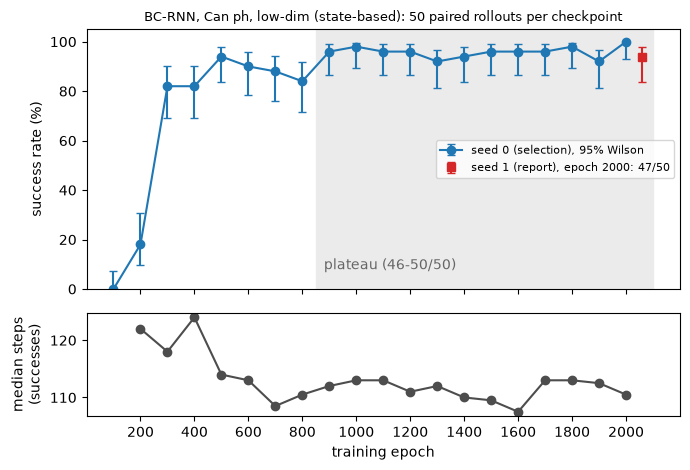

In [3]:
_, S1 = to_matrix(rows, seed=1, key="success")      # selected checkpoint only
_, T1 = to_matrix(rows, seed=1, key="steps")
assert S1.shape == (1, 50)
k1, n1 = int(S1.sum()), S1.shape[1]
lo, hi = wilson(k, 50)
lo1, hi1 = wilson(k1, n1)
p0 = k / 50
med_steps = [np.median(T0[i][S0[i]]) if S0[i].any() else np.nan for i in range(len(epochs))]

for e, kk, l, h in zip(epochs, k, lo, hi):
    print(f"epoch {e:4d}: {kk:2d}/50  95% Wilson {100*l:5.1f}-{100*h:5.1f}%")
print(f"report, epoch 2000, seed 1: {k1}/{n1} = {100*k1/n1:.0f}%, "
      f"95% Wilson {100*lo1:.1f}-{100*hi1:.1f}%")

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(7, 4.8), sharex=True,
                              gridspec_kw={"height_ratios": [3, 1.2]})
ax.errorbar(epochs, 100 * p0, yerr=[100 * (p0 - lo), 100 * (hi - p0)], fmt="o-", color="C0",
            capsize=3, label="seed 0 (selection), 95% Wilson")
ax.errorbar([2060], [100 * k1 / n1], yerr=[[100 * (k1 / n1 - lo1)], [100 * (hi1 - k1 / n1)]],
            fmt="s", color="C3", capsize=3, label=f"seed 1 (report), epoch 2000: {k1}/{n1}")
ax.axvspan(850, 2100, color="0.92", zorder=0)
ax.text(880, 8, "plateau (46-50/50)", color="0.4")
ax.set_ylabel("success rate (%)")
ax.set_ylim(0, 105)
ax.legend(loc="center right", fontsize=8)
ax.set_title("BC-RNN, Can ph, low-dim (state-based): 50 paired rollouts per checkpoint", fontsize=9)
ax2.plot(epochs, med_steps, "o-", color="0.3")
ax2.set_ylabel("median steps\n(successes)")
ax2.set_xlabel("training epoch")
ax2.set_xticks(epochs[1::2])
fig.tight_layout()
fig.savefig(FIG_DIR / "can_eval_success.png", dpi=110)
plt.show()

**Reading the result.**

- Success climbs from 0 (epoch 100) to 41/50 at epoch 300, then sits on a **plateau of
  46–50/50 from epoch 900 on**. The validation-loss minimum (≈300) is far from the best
  checkpoints, as on Lift: offline loss does not rank closed-loop policies.
- **Selection rule** (fixed before looking, as on Lift): most successes on seed 0, ties to
  the later checkpoint → epoch 2000 (50/50).
- **Winner's curse, observed.** The same checkpoint scores **47/50 on seed 1**. Picking the
  maximum of 20 noisy scores inflated the seed-0 number by 3 episodes; seed 1 is the number
  to report. Both intervals overlap widely, so 47/50 is consistent with the paper's
  near-100% for this setting, but 50 episodes cannot separate 94% from 98%.
- Successful episodes take about 110–120 steps, the same as the demos (median 115): the
  policy reproduces the demonstrated tempo rather than finding a faster strategy.

**Predict (2).** Epoch 2000 scored 50/50 and epoch 1900 46/50 on the same 50 initial states.
Is that difference significant under the exact McNemar test? Estimate the p-value before
running the cell (hint: 00b, section 3).

## 2. Is the plateau really flat? Paired tests against the selected checkpoint

In [4]:
sel = len(epochs) - 1                               # epoch 2000
print("vs epoch 2000   only-2000  only-other   p (exact McNemar)")
for i, e in enumerate(epochs[:-1]):
    a, b = discordant(S0[sel], S0[i])
    print(f"epoch {e:4d}:      {len(a):5d}      {len(b):5d}        {mcnemar_exact(S0[sel], S0[i]):.3f}")

vs epoch 2000   only-2000  only-other   p (exact McNemar)
epoch  100:         50          0        0.000
epoch  200:         41          0        0.000
epoch  300:          9          0        0.004
epoch  400:          9          0        0.004
epoch  500:          3          0        0.250
epoch  600:          5          0        0.062
epoch  700:          6          0        0.031
epoch  800:          8          0        0.008
epoch  900:          2          0        0.500
epoch 1000:          1          0        1.000
epoch 1100:          2          0        0.500
epoch 1200:          2          0        0.500
epoch 1300:          4          0        0.125
epoch 1400:          3          0        0.250
epoch 1500:          2          0        0.500
epoch 1600:          2          0        0.500
epoch 1700:          2          0        0.500
epoch 1800:          1          0        1.000
epoch 1900:          4          0        0.125


**Reading the result.** Epochs 700 and 800 are significantly worse than 2000 (6–0 and 8–0
discordant splits), but **no checkpoint from epoch 900 on differs** from it (smallest
p = 0.125 for the 4–0 splits of 1300 and 1900). Near 95% success only a few of 50 episodes
are discordant, and even an all-one-way split needs at least 6 discordant episodes for
p < 0.05 (5–0 gives 0.0625, as for epoch 600).
Epoch 2000 is "a member of the plateau", not "the best epoch". This is the evaluation-budget
lesson from 00b again: phase-2 comparisons must avoid ceiling tasks or use more episodes.

**Predict (3).** Look at the plateau checkpoints (900–2000). Do their failures fall on the
same few initial states (some starts are hard), or are they spread over many states
(random slips)? What would each pattern suggest about the cause?

## 3. Which initial states fail

plateau failures per episode (nonzero): {0: 1, 1: 1, 4: 5, 8: 2, 13: 3, 19: 1, 21: 1, 25: 1, 30: 1, 34: 2, 36: 4, 40: 1, 47: 2}
episodes failing in >=3 of 12 plateau checkpoints: [4, 13, 36] -> 12 of 25 plateau failures


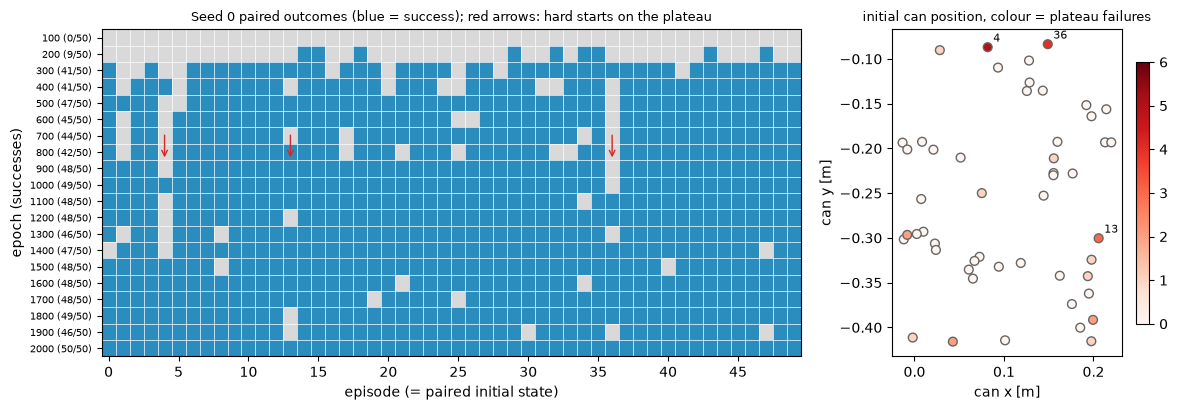

In [5]:
row = {e: i for i, e in enumerate(epochs)}
plateau = epochs >= 900
fails = (~S0[plateau]).sum(axis=0)                   # per episode, over 12 plateau checkpoints
hard = np.flatnonzero(fails >= 3)
print("plateau failures per episode (nonzero):",
      {int(j): int(fails[j]) for j in np.flatnonzero(fails)})
print("episodes failing in >=3 of 12 plateau checkpoints:", hard.tolist(),
      f"-> {fails[hard].sum()} of {fails.sum()} plateau failures")
assert (fails[hard].sum(), fails.sum()) == (12, 25)

xy = {r["episode"]: (r["obj_x"], r["obj_y"]) for r in rows if r["seed"] == 0 and r["epoch"] == 2000}
XY = np.array([xy[i] for i in range(50)])

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [2.4, 1]})
ax.imshow(S0, aspect="auto", cmap=ListedColormap(["#d9d9d9", "#2b8cbe"]), interpolation="nearest")
ax.set_yticks(range(len(epochs)), [f"{e} ({s}/50)" for e, s in zip(epochs, k)], fontsize=7)
ax.set_xticks(range(0, 50, 5))
ax.set_xlabel("episode (= paired initial state)")
ax.set_ylabel("epoch (successes)")
ax.set_xticks(np.arange(-0.5, 50, 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(epochs), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=0.5)
ax.tick_params(which="minor", length=0)
for j in hard:
    ax.annotate("", xy=(j, row[900] - 0.5), xytext=(j, row[900] - 2.2),
                arrowprops=dict(arrowstyle="->", color="C3"))
ax.set_title("Seed 0 paired outcomes (blue = success); red arrows: hard starts on the plateau",
             fontsize=9)

sc = ax2.scatter(XY[:, 0], XY[:, 1], c=fails, cmap="Reds", vmin=0, vmax=6, s=40, edgecolor="0.4")
for j in hard:
    ax2.annotate(str(j), XY[j], textcoords="offset points", xytext=(4, 4), fontsize=8)
ax2.set_xlabel("can x [m]")
ax2.set_ylabel("can y [m]")
ax2.set_aspect("equal")
ax2.set_title("initial can position, colour = plateau failures", fontsize=9)
fig.colorbar(sc, ax=ax2, shrink=0.8)
fig.tight_layout()
fig.savefig(FIG_DIR / "can_eval_paired.png", dpi=110)
plt.show()

**Reading the result.** Plateau failures concentrate on a few starts: episode 4 fails in 5 of
12 plateau checkpoints, episode 36 in 4 and episode 13 in 3, while most other failures
appear once or twice. These three starts account for 12 of the 25 plateau failures. In the
scatter, episodes 4 and 36 both start at the +y edge of the start region (y ≈ −0.09 m, the
side nearest the bin), while 13 is mid-range. Two points are a hint, not evidence: the
initial yaw (not stored in the CSV) and the grasp contact are equally plausible causes, and
a targeted check would evaluate more starts near that edge.

## 4. What failure looks like

Clips: 160 px, every 2nd (success) or 4th (failure) frame, played at 10 fps, so 2× and 4×
real time. Cut by `jobs/make_clips.py` from the full MP4s in run storage.

| Success (epoch 2000, episode 0, 135 steps) | Failure (epoch 1300, episode 4) | Failure (epoch 1300, episode 36) |
|---|---|---|
| ![success](../docs/media/can_success.webp) | ![fail ep 4](../docs/media/can_fail_ep4.webp) | ![fail ep 36](../docs/media/can_fail_ep36.webp) |

**Observed failure mode (both clips): the can is lost during transport and never re-grasped.**

- Episode 4: the can is grasped tilted, slips while the arm swings to the bin, and comes to
  rest lying on the bin's left wall.
- Episode 36: the grasp looks clean, but the can is released over the wrong (front-left)
  compartment.
- Afterwards the arm keeps hovering over the target compartment (front right) until the
  horizon. The demos contain no recovery from a dropped can, so the policy has never seen
  "can lying elsewhere, gripper empty" and continues the placing motion.

This is compounding error with no recovery data, the main known weakness of BC on ph
(proficient-human) demonstrations. The seed-1 failures (episodes 22, 25, 33) were not
filmed; filming them is a cheap check of whether the same mode dominates.

## 5. Open questions (answer in chat; conclusions go to docs/BASELINE.md)

1. Report 47/50 or 50/50? Write the one-sentence result for the README, including the
   interval and what "state-based" means.
2. The failures are drops without recovery. Which phase-3 lever would you expect to help
   most: more ph demos, the mh (mixed-quality) demos that contain corrections, or action
   chunking? Why?
3. Phase 2 will compare ACT and Diffusion Policy with BC-RNN. Given section 2, is Can a good
   task for that comparison? What would you change in the evaluation?